# Phase 5: EDA (exploratory data analysis)

Look at the cleaned data with charts before modelling it. Every chart is here because it drives a later decision.

This is the cleaned sample from Phase 4 (6,000 photos, 6,228 boxes), looked at **before** splitting. We only count and look here, nothing is tuned, so no test information leaks.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Rectangle
from PIL import Image

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config

src = config.PROCESSED / "04_clean"
images, boxes = pd.read_csv(src / "images_clean.csv"), pd.read_csv(src / "boxes_clean.csv")

CLASSES = ["D00", "D10", "D20", "D40"]
COLORS = ["#3b82f6", "#a855f7", "#f59e0b", "#ef4444"]
NAMES = {"D00": "D00 · Longitudinal crack (along the road)", "D10": "D10 · Transverse crack (across the road)",
         "D20": "D20 · Alligator crack (web of cracks)", "D40": "D40 · Pothole"}
LEGEND = [plt.Rectangle((0, 0), 1, 1, color=c, label=NAMES[k]) for k, c in zip(CLASSES, COLORS)]
CROP_LINE = 1 - config.CROP_KEEP  # we plan to keep only the bottom 5/8 of each photo: everything above 0.375 is cut

b = boxes.merge(images[["image_id", "country", "width", "height"]], on="image_id")
b["bw"], b["bh"] = b.xmax - b.xmin, b.ymax - b.ymin
b["area_sq"] = b.bw * b.bh / (b.width * b.height / 64)  # box area in "squares" (one square = 1/64 of a photo after the crop)
b["cy"] = (b.ymin + b.ymax) / 2 / b.height  # vertical centre of the box: 0 = top of the photo, 1 = bottom
print(len(images), "photos,", len(b), "boxes")

6000 photos, 6228 boxes


## 1. Boxes per class, per country

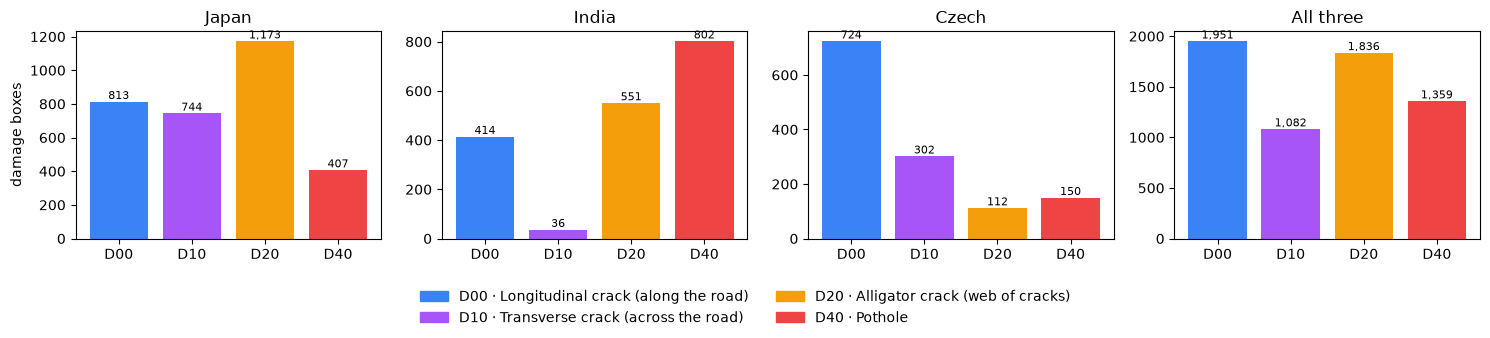

share of all boxes: {'D00': 0.313, 'D10': 0.174, 'D20': 0.295, 'D40': 0.218}


In [2]:
counts = b.groupby(["country", "cls"]).size().unstack(fill_value=0)[CLASSES].loc[config.COUNTRIES]
counts.loc["All three"] = counts.sum()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (name, row) in zip(axes, counts.iterrows()):
    ax.bar(CLASSES, row, color=COLORS)
    ax.set_title(name)
    for i, v in enumerate(row):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[0].set_ylabel("damage boxes")
fig.legend(handles=LEGEND, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.17, 1, 1))
plt.show()
print("share of all boxes:", (counts.loc["All three"] / counts.loc["All three"].sum()).round(3).to_dict())

**What it shows:** the damage boxes are fairly balanced between the four classes: D00 31%, D20 29%, D40 22%, D10 17%. D10 (transverse crack) is the rarest. The countries differ a lot: India has only **36** D10 boxes, and Czech has few D20 (112) and D40 (150). Most of the D10 boxes come from Japan.

**So:** damage boxes are only mildly imbalanced. The big imbalance will come later, at square level, because most squares contain no damage at all. We'll still expect D10 to be the weakest class, and we'll report scores per country, since India and Czech can't tell us much about some classes.

## 2. Photos with and without damage

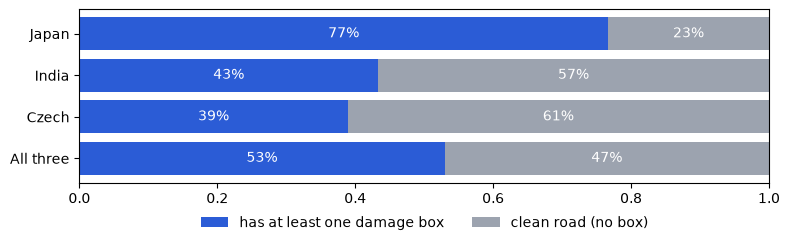

In [3]:
images["has_damage"] = images["image_id"].isin(b["image_id"])
share = images.groupby("country")["has_damage"].mean().loc[config.COUNTRIES]
share["All three"] = images["has_damage"].mean()

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(share.index, share, color="#2b5cd6", label="has at least one damage box")
ax.barh(share.index, 1 - share, left=share, color="#9ca3af", label="clean road (no box)")
for i, v in enumerate(share):
    ax.text(v / 2, i, f"{v:.0%}", ha="center", va="center", color="white")
    ax.text(v + (1 - v) / 2, i, f"{1 - v:.0%}", ha="center", va="center", color="white")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**What it shows:** 53% of the photos contain at least one damage box, and 47% are clean road. It depends heavily on country: Japan 77% damage, India 43%, Czech 39%.

**So:** clean photos are a large part of the data, and they are our "none" examples. And even in damaged photos the boxes are small, so "none" will still dominate at the square level. Phase 6 should count it; we expect around 85–90%.

## 3. How big is each box, measured in squares?

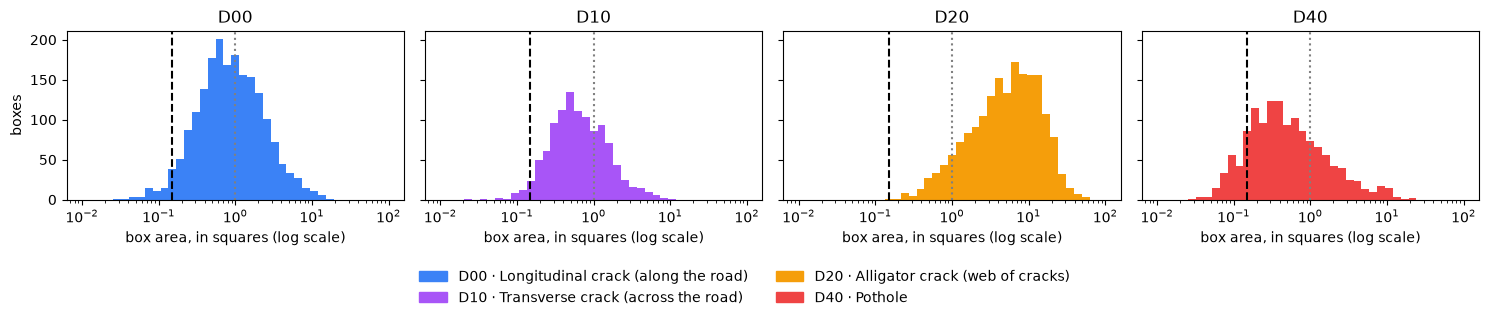

,median,below_015,below_1
cls,,,
D00,0.829,0.033,0.568
D10,0.607,0.033,0.703
D20,5.519,0.001,0.089
D40,0.426,0.137,0.742


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, k, c in zip(axes, CLASSES, COLORS):
    ax.hist(b.loc[b.cls == k, "area_sq"], bins=np.logspace(-2, 2, 40), color=c)
    ax.set_xscale("log")
    ax.axvline(0.15, color="black", linestyle="--")
    ax.axvline(1, color="gray", linestyle=":")
    ax.set_title(k)
    ax.set_xlabel("box area, in squares (log scale)")
axes[0].set_ylabel("boxes")
fig.legend(handles=LEGEND, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.17, 1, 1))
plt.show()

size = b.groupby("cls")["area_sq"].agg(median="median", below_015=lambda s: (s < 0.15).mean(), below_1=lambda s: (s < 1).mean()).loc[CLASSES]
size.round(3)

**What it shows:** box size in **squares** (the 80 × 80 pieces we'll cut each photo into; one square is 1/64 of a photo). Median size: D20 5.5 squares (large), D00 0.8, D10 0.6, D40 0.4 (small). **74% of potholes and 70% of transverse cracks are smaller than a single square.**

The dashed line marks 0.15 squares and the dotted line marks 1 square. Our labelling rule says a box must cover at least 15% of a square to label it, so **any box below that line can never label any square**. That is **13.7% of the potholes** (about 190 boxes), 3.3% of D00 and D10, and almost none of D20.

**So:** the 15% rule would throw away a noticeable share of small potholes. In Phase 6, count how many boxes end up with no square, and if it's too many, use the 10% fallback from the guide.

## 4. What shape is each class?

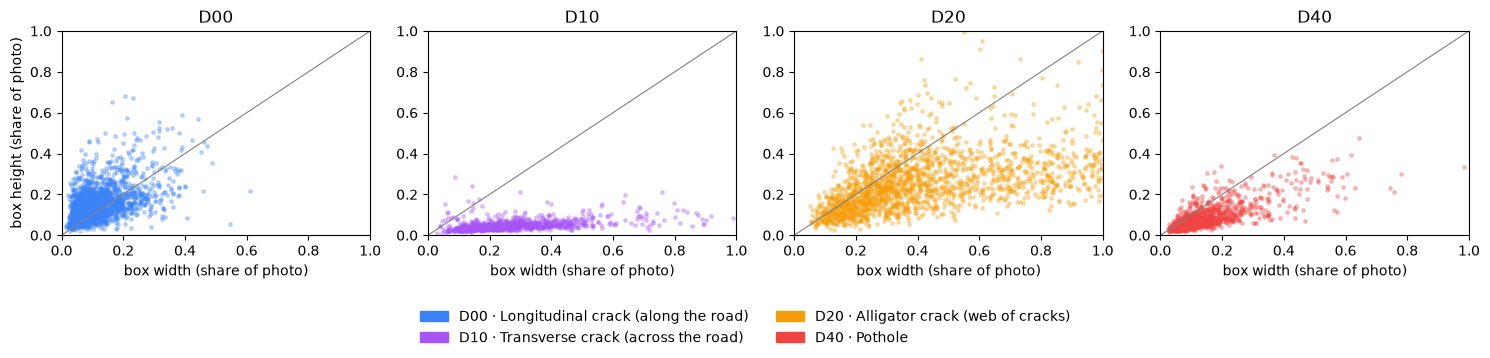

median width / height of a box (above 1 = wider than tall):


{'D00': 0.72, 'D10': 5.23, 'D20': 1.48, 'D40': 1.68}

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, k, c in zip(axes, CLASSES, COLORS):
    d = b[b.cls == k]
    ax.scatter(d.bw / d.width, d.bh / d.height, s=6, alpha=0.3, color=c)
    ax.plot([0, 1], [0, 1], color="gray", linewidth=0.8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(k)
    ax.set_xlabel("box width (share of photo)")
axes[0].set_ylabel("box height (share of photo)")
fig.legend(handles=LEGEND, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.17, 1, 1))
plt.show()

wide = b.assign(wide_vs_tall=b.bw / b.bh).groupby("cls")["wide_vs_tall"].median().loc[CLASSES]
print("median width / height of a box (above 1 = wider than tall):")
wide.round(2).to_dict()

**What it shows:** the shape of the boxes for each class, width against height (points above the grey diagonal are taller than wide). **D10 boxes are long and flat** (median width is 5.2 times the height), which fits "crack across the road". D00 boxes are taller than wide, but only a bit (median width/height 0.72). D20 (1.5) and D40 (1.7) are wider than tall and overlap a lot with each other.

These are bounding boxes, so a diagonal crack gets a squarish box; treat the shape as a hint.

**So:** D00 and D10 differ in shape and direction, so edge-direction features (HOG) have something to pick up. D20 and D40 look alike in shape, so expect those two to be confused. That is the confusion we predicted in the hypotheses.

## 5. Where in the photo is the damage?

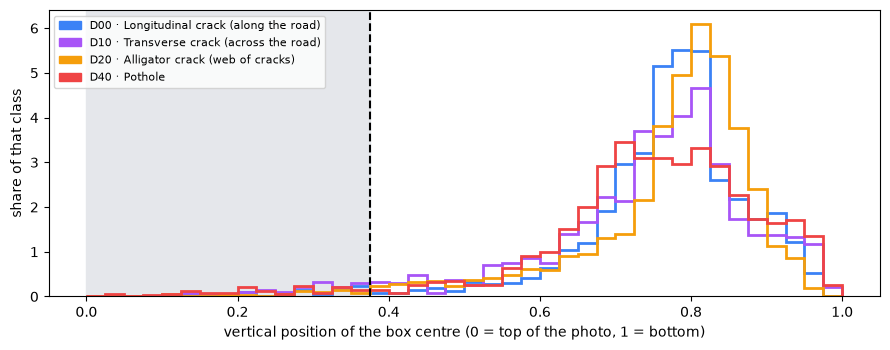

,centre_above_line,box_area_cut_off
cls,,
D00,0.021,0.021
D10,0.040,0.039
D20,0.019,0.033
D40,0.038,0.037
all,0.027,0.031


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(0, CROP_LINE, color="#e5e7eb")
for k, c in zip(CLASSES, COLORS):
    ax.hist(b.loc[b.cls == k, "cy"], bins=np.linspace(0, 1, 41), histtype="step", color=c, linewidth=2, density=True)
ax.axvline(CROP_LINE, color="black", linestyle="--")
ax.set_xlabel("vertical position of the box centre (0 = top of the photo, 1 = bottom)")
ax.set_ylabel("share of that class")
ax.legend(handles=LEGEND, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

b["area_lost"] = b.bw * np.clip(np.minimum(b.ymax, CROP_LINE * b.height) - b.ymin, 0, None) / (b.bw * b.bh)
crop = pd.DataFrame({
    "centre_above_line": b.groupby("cls").apply(lambda d: (d.cy < CROP_LINE).mean(), include_groups=False),
    "box_area_cut_off": b.groupby("cls")["area_lost"].mean(),
}).loc[CLASSES]
crop.loc["all"] = [(b.cy < CROP_LINE).mean(), b["area_lost"].mean()]
crop.round(3)

**What it shows:** where the damage sits in the photo (0 = top, 1 = bottom). All four classes peak low in the photo, at about 0.8 of the way down. The grey area is the top 3/8 that our crop would cut off. Only **2.7%** of box centres are in that area, and cutting it removes only **3.1%** of the total box area (D10 3.9%, D40 3.7%, D00 2.1%).

**So:** the plan to keep only the bottom 5/8 of each photo is confirmed. We lose about 3% of the damage and remove mostly sky and buildings, which can only add "none" squares.

## 6. How many boxes does a photo have?

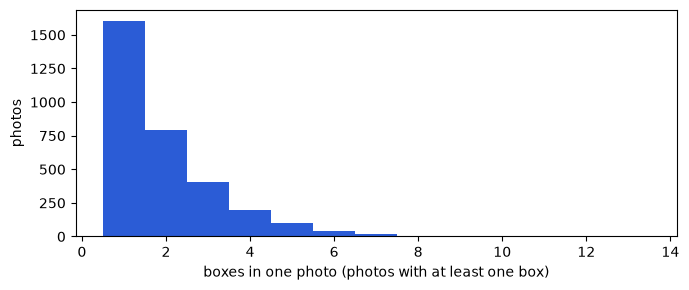

{1: 1605, 2: 793, 3: 402, 4: 200, 5: 100, 6: 44, 7: 16, 8: 7, 9: 7, 10: 1, 13: 2}
photos with 2+ boxes: 49.5%


In [7]:
per_photo = b.groupby("image_id").size()
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(per_photo, bins=np.arange(0.5, per_photo.max() + 1.5), color="#2b5cd6")
ax.set_xlabel("boxes in one photo (photos with at least one box)")
ax.set_ylabel("photos")
plt.tight_layout()
plt.show()
print(per_photo.value_counts().sort_index().to_dict())
print("photos with 2+ boxes:", f"{(per_photo >= 2).mean():.1%}")

**What it shows:** of the 3,177 photos that have boxes, half (50.5%) have just one, the other half have two or more, and a few have up to 13.

**So:** many photos have several damage spots, which fits with many squares per photo and the next chart.

## 7. Which classes appear together in the same photo?

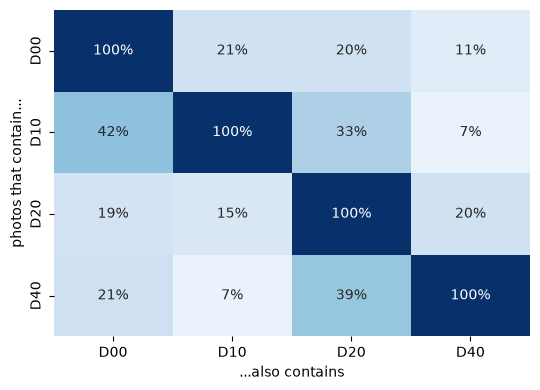

In [8]:
present = b.assign(v=1).pivot_table(index="image_id", columns="cls", values="v", aggfunc="max", fill_value=0)[CLASSES]
together = pd.DataFrame({r: {c: ((present[r] == 1) & (present[c] == 1)).sum() / present[r].sum() for c in CLASSES} for r in CLASSES}).T
plt.figure(figsize=(5.5, 4))
sns.heatmap(together, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False)
plt.xlabel("...also contains")
plt.ylabel("photos that contain...")
plt.tight_layout()
plt.show()

**What it shows:** among photos containing the class on the left, the share that also contain the class at the top. Cracks often appear together: **42% of D10 photos also have a D00**, and **39% of D40 photos also have a D20** (potholes sit inside cracked areas). D10 and D40 almost never share a photo (7%). Overall 31% of damaged photos have two or more different classes.

**So:** one square can be touched by boxes of two classes. That is why our labelling rule takes the most serious class when several qualify (pothole > alligator > transverse > longitudinal). Phase 6 should count how often this happens. It also explains the likely confusions: D00 with D10, and D20 with D40.

## 8. Photo sizes per country

In [9]:
images.groupby(["country", "width"]).size().rename("photos").to_frame()

photos
country width        
Czech   600      2000
India   720      2000
Japan   540        28
        600      1938
        1024       25
        1080        9

**What it shows:** every photo is square, but not the same size: Czech 600, India 720, Japan mostly 600 but also 540 (28 photos), 1024 (25) and 1080 (9).

**So:** the crop and the box coordinates must work in **fractions of the photo**, not fixed pixels. The bottom 5/8 of a 1080 photo is not the same pixel range as in a 600 photo, and boxes must be rescaled by the right photo size.

## 9. A few real examples per class (our boxes drawn on top)

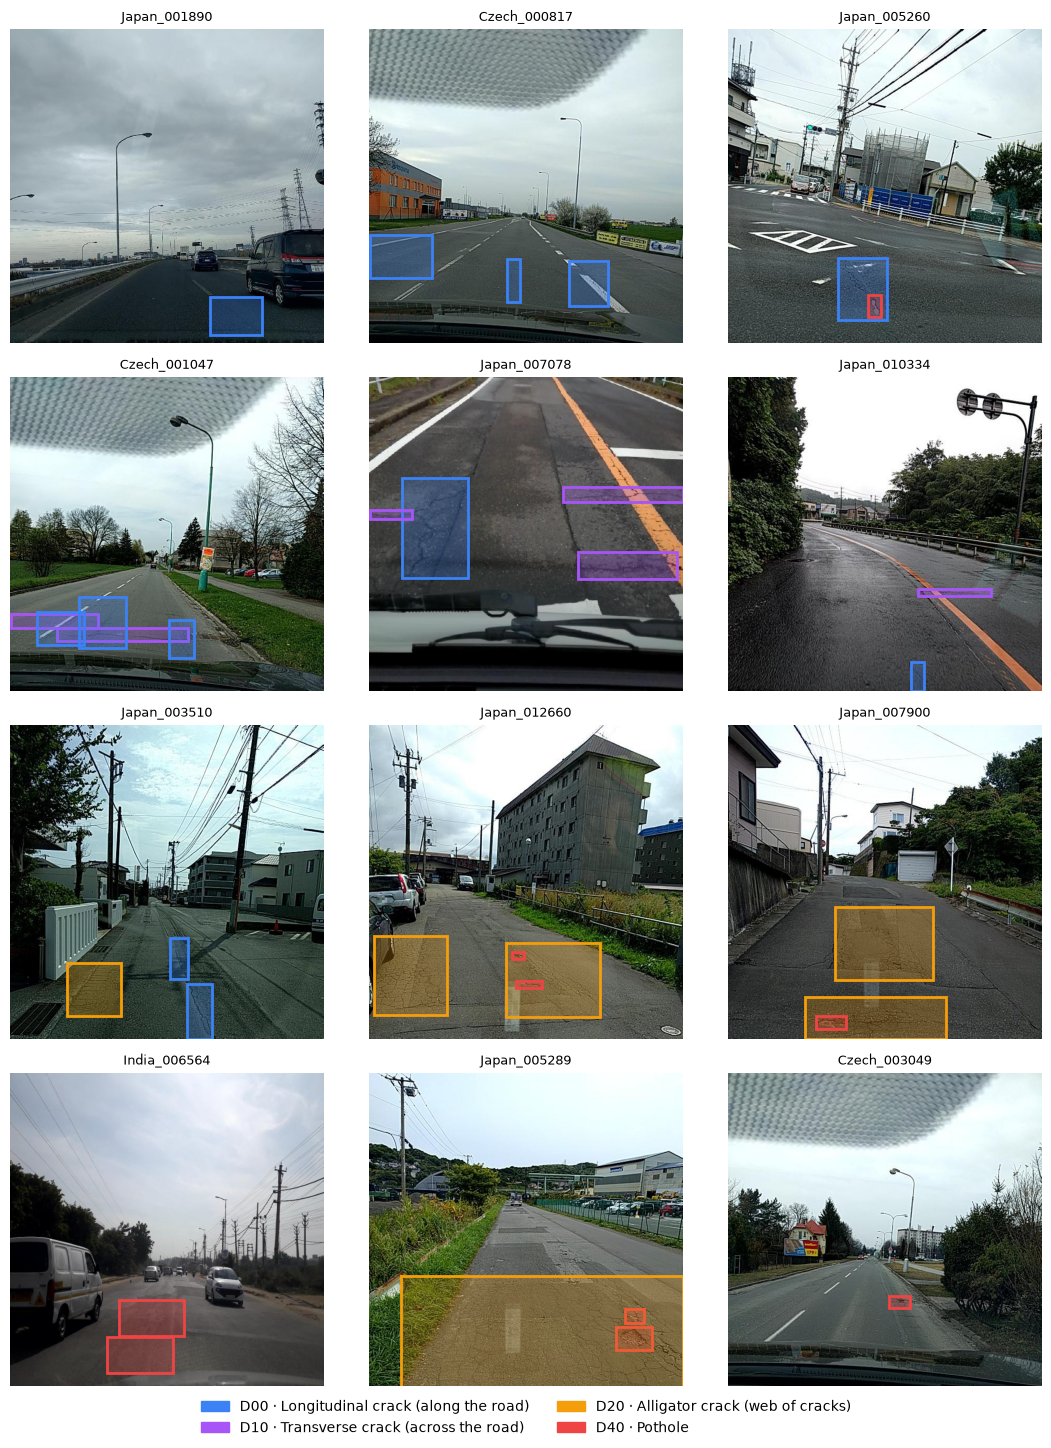

In [10]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(4, 3, figsize=(11, 14.5))
for row, (k, c) in zip(axes, zip(CLASSES, COLORS)):
    ids = rng.choice(b.loc[b.cls == k, "image_id"].unique(), size=3, replace=False)
    for ax, iid in zip(row, ids):
        info = images.set_index("image_id").loc[iid]
        ax.imshow(Image.open(config.RAW / info["path"]).convert("RGB"))
        for r in b[b.image_id == iid].itertuples():
            col = COLORS[CLASSES.index(r.cls)]
            ax.add_patch(Rectangle((r.xmin, r.ymin), r.bw, r.bh, facecolor=col, alpha=0.25))
            ax.add_patch(Rectangle((r.xmin, r.ymin), r.bw, r.bh, fill=False, edgecolor=col, linewidth=2))
        ax.set_title(f"{iid}", fontsize=9)
        ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

**What it shows:** random examples for each class, with our boxes drawn. Things to notice:
- Boxes are often small and the damage is hard to see by eye, so the task is hard.
- **The car itself is in the picture:** the Czech examples show windshield glass across the top, and `Japan_007078` shows the car's bonnet and wipers across the bottom.
- A pothole box often sits inside an alligator-crack box (`Japan_012660`, `Japan_005289`).

**So:** the top crop also removes the windshield glass in the Czech photos, but bonnet and dashboard at the bottom stay in. Squares showing car parts will be labelled "none", which adds some noise. The nested D40-in-D20 boxes confirm the need for the tie-break rule.

## What the EDA tells us to do

| Finding | Decision for the next phases |
|---|---|
| Boxes are fairly balanced, D10 is the rarest (India only 36) | Expect D10 to be weakest. Score per country as well as overall. |
| About half the photos are clean, and boxes are small | "None" will dominate the squares. Balance the training set (Phase 8), and judge with macro F1. |
| 13.7% of potholes are smaller than 15% of a square | In Phase 6, count boxes that get no square. If too many, use a 10% threshold. |
| D10 is long and flat, D00 tall, D20 and D40 look alike | HOG (edge direction) should separate D00 from D10. Expect D20 and D40 to be confused. |
| Only 2.7% of damage is in the top 3/8 of the photo | Crop to the bottom 5/8. |
| Boxes of different classes often share a photo and overlap | Keep the "most serious class wins" rule. Count the conflicts in Phase 6. |
| Photos are different sizes (540 to 1080) | Crop and scale by fractions, not pixels. |
| Cars' bonnets and windshields appear in some photos | Accept as noise. Mention it as a limit in the report. |